# Train RF-DETR with Random Erasing Only (Local)

Local RF-DETR counterpart to the YOLO / RT-DETR notebooks.

Fine-tunes an RF-DETR detector (`RFDETRMedium`, COCO-pretrained) on the African wildlife dataset.

Same as `RFDETR_erasing.ipynb` but **without the horizontal flip**, so random erasing is the only added augmentation. Comparing the two runs shows how much the flip contributes.

**Random erasing:** during training a random rectangle of each image is blanked out, so the model learns to recognise partly hidden animals (behind grass, trees or other animals) instead of relying on one distinctive patch.

- **Dataset:** `data/wildlife_dataset` (images/labels with train/val/test splits)
- **Final trained model:** `ai-applications/trained_models`

## Dataset format

```text
wildlife_dataset/
├── wildlife_dataset.yaml
├── images/train
├── images/val
├── images/test
├── labels/train
├── labels/val
└── labels/test
```

RF-DETR reads the split paths from `wildlife_dataset.yaml` and finds each split's labels by swapping `images` for `labels` in the path.

Each label file uses:

```text
class_id center_x center_y width height
```

All coordinates must be normalized from 0 to 1.

In [1]:
# albumentations provides the Erasing transform (comments can't go on the %pip line: pip would read them as package names)
%pip install -q rfdetr supervision pyyaml "albumentations>=1.4.24,<3.0.0"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import time
import shutil
import yaml
import torch
import numpy as np
import pandas as pd
import supervision as sv
from pathlib import Path
from supervision.metrics import MeanAveragePrecision, Precision, Recall, AveragingMethod
from rfdetr import RFDETRMedium, from_checkpoint
import rfdetr.datasets.yolo as rfdetr_yolo

TEXT, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'

print('CUDA available:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA available: True
GPU: NVIDIA GeForce RTX 3070


In [3]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]  # ai-applications/vs_notebooks -> repo root

DATASET_DIR = PROJECT_ROOT / 'data' / 'wildlife_dataset'
TRAINED_MODEL_DIR = PROJECT_ROOT / 'ai-applications' / 'trained_models'
RESULTS_DIR = PROJECT_ROOT / 'ai-applications' / 'training_results' / 'rf-detr-erasing-only'
RUNS_DIR = PROJECT_ROOT / 'ai-applications' / 'rfdetr_runs'
RUN_NAME = 'wildlife_rfdetr_medium_erasing_only'
OUTPUT_DIR = RUNS_DIR / RUN_NAME

MODEL_NAME = 'RF-DETR-M + erasing only'
SEED = 14  # fixed seed; re-runs land close but not bit-identical (deterministic GPU kernels are off for speed)

assert DATASET_DIR.exists(), f'Dataset not found: {DATASET_DIR}'
TRAINED_MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Dataset:', DATASET_DIR)
print('Run output dir:', OUTPUT_DIR)
print('Results dir:', RESULTS_DIR)
print('Trained model dir:', TRAINED_MODEL_DIR)

Dataset: C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset
Run output dir: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\rfdetr_runs\wildlife_rfdetr_medium_erasing_only
Results dir: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\training_results\rf-detr-erasing-only
Trained model dir: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\trained_models


In [4]:
DATA = DATASET_DIR / 'wildlife_dataset.yaml'

# Point the dataset YAML at this machine's dataset folder
with open(DATA, 'r') as f:
    dataset_config = yaml.safe_load(f)

dataset_config['path'] = str(DATASET_DIR)

with open(DATA, 'w') as f:
    yaml.safe_dump(dataset_config, f, sort_keys=False)

# Class names come from the YAML so the model head always matches the label ids
# (a hard-coded list that is too short makes training crash with a CUDA device-side assert)
names = dataset_config['names']
CLASS_NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)

# RF-DETR only looks for data.yaml / data.yml in the dataset root; let it find wildlife_dataset.yaml too
if DATA.name not in rfdetr_yolo.REQUIRED_YOLO_YAML_FILES:
    rfdetr_yolo.REQUIRED_YOLO_YAML_FILES.insert(0, DATA.name)

print('Dataset YAML:', DATA)
print(dataset_config)
print('Classes:', CLASS_NAMES)

Dataset YAML: C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset\wildlife_dataset.yaml
{'path': 'C:\\Users\\zheng\\Documents\\ISY5002-PRS-G14\\data\\wildlife_dataset', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': {0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra', 4: 'okapi', 5: 'leopard', 6: 'cheetah'}}
Classes: ['buffalo', 'elephant', 'rhino', 'zebra', 'okapi', 'leopard', 'cheetah']


In [5]:
train_dir = DATASET_DIR / 'images' / 'train'
val_dir = DATASET_DIR / 'images' / 'val'
test_dir = DATASET_DIR / 'images' / 'test'

print('Dataset root:', DATASET_DIR)
print('Training images:', len([p for p in train_dir.iterdir() if p.is_file()]))
print('Validation images:', len([p for p in val_dir.iterdir() if p.is_file()]))
print('Test images:', len([p for p in test_dir.iterdir() if p.is_file()]))
print('Classes:', CLASS_NAMES)

Dataset root: C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset
Training images: 2652
Validation images: 332
Test images: 331
Classes: ['buffalo', 'elephant', 'rhino', 'zebra', 'okapi', 'leopard', 'cheetah']


## Data augmentation: random erasing only

RF-DETR passes `aug_config` to [Albumentations](https://albumentations.ai). `Erasing` is Albumentations' version of torchvision's `RandomErasing`: with probability `p` it fills one random rectangle covering `scale` of the image (aspect ratio within `ratio`). It only changes pixels, so the bounding boxes and labels stay the same.

`aug_config` replaces RF-DETR's default augmentation (a horizontal flip), so leaving the flip out of `AUG_CONFIG` turns it off. RF-DETR's random resize / crop is applied separately and is kept either way.

[2026-10-22 00:02:49] [INFO] rf-detr - Built 1 Albumentations transforms from config


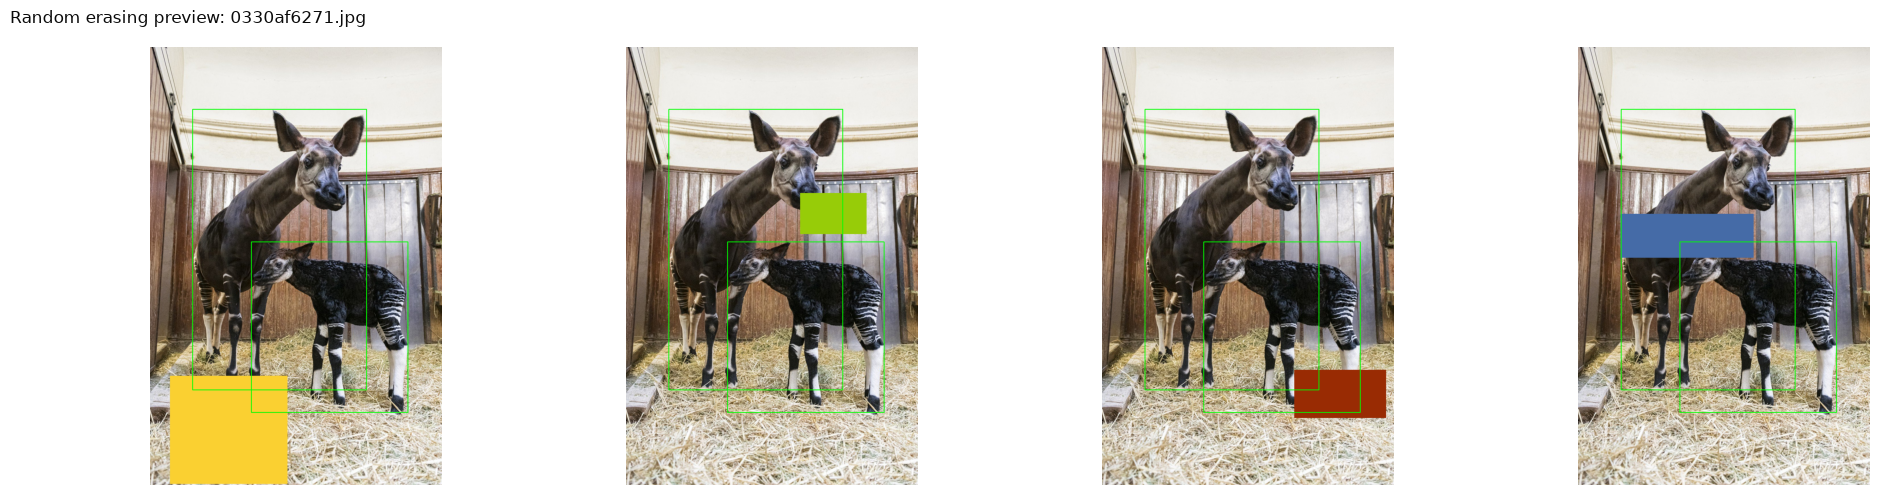

In [6]:
# No HorizontalFlip: aug_config replaces RF-DETR's default flip, so erasing is the only augmentation
AUG_CONFIG = {
    'Erasing': {
        'scale': (0.02, 0.1),  # erased area as a fraction of the image; above ~0.1 it often hides most of a small animal
        'ratio': (0.3, 3.3),  # aspect ratio range of the erased rectangle (torchvision default)
        'fill': 'random_uniform',  # one random solid colour per rectangle, so the model can't learn 'black patch'; 'random' = per-pixel noise
        'p': 0.5
    }
}

# Preview: the same training image through the erasing step 4 times (green boxes = labels, unchanged by erasing)
from rfdetr.datasets.transforms import AlbumentationsWrapper

preview_ds = sv.DetectionDataset.from_yolo(
    images_directory_path=str(train_dir),
    annotations_directory_path=str(DATASET_DIR / 'labels' / 'train'),
    data_yaml_path=str(DATA)
)
preview_path, preview_image, preview_target = preview_ds[0]
erasing = AlbumentationsWrapper.from_config({'Erasing': {**AUG_CONFIG['Erasing'], 'p': 1.0}})[0]  # p=1 so every sample is erased

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax in axes:
    image = Image.fromarray(cv2.cvtColor(preview_image, cv2.COLOR_BGR2RGB))
    target = {'boxes': torch.tensor(preview_target.xyxy, dtype=torch.float32), 'labels': torch.tensor(preview_target.class_id)}
    image, target = erasing(image, target)
    shown = sv.Detections(xyxy=target['boxes'].numpy(), class_id=target['labels'].numpy())
    ax.imshow(sv.BoxAnnotator(color=sv.Color.GREEN).annotate(np.array(image), shown))
    ax.axis('off')
fig.suptitle(f'Random erasing preview: {Path(preview_path).name}', x=0, ha='left', fontsize=12, color=TEXT)
fig.tight_layout()
plt.show()

In [7]:
# num_classes must be set explicitly: RF-DETR can't auto-detect it from the images/<split> layout
# Seed before building the model: the new detection head is randomly initialized.
# Plain torch.manual_seed instead of rfdetr's seed_all, which also forces slow deterministic CUDA kernels.
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True  # let cuDNN pick the fastest kernels for this GPU
model = RFDETRMedium(num_classes=len(CLASS_NAMES))
print(f'Model initialized: RFDETRMedium (COCO-pretrained weights), {len(CLASS_NAMES)} classes')

[2026-10-22 00:02:51] [INFO] rf-detr - File C:\Users\zheng\.roboflow\models\rf-detr-medium.pth already exists with correct MD5 hash.


[2026-10-22 00:02:51] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-22 00:02:51] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-22 00:02:52] [INFO] rf-detr - File C:\Users\zheng\.roboflow\models\rf-detr-medium.pth already exists with correct MD5 hash.


[2026-10-22 00:02:54] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 7. The detection head will be re-initialized to 7 classes.


Model initialized: RFDETRMedium (COCO-pretrained weights), 7 classes


In [8]:
start_time = time.time()

model.train(
    dataset_dir=str(DATASET_DIR),
    dataset_file='yolo',
    class_names=CLASS_NAMES,
    epochs=50,
    batch_size=8,
    grad_accum_steps=2,  # effective batch size 16; drop to batch_size=4, grad_accum_steps=4 on CUDA out-of-memory
    lr=0.00005,
    aug_config=AUG_CONFIG,  # erasing only; replaces RF-DETR's default horizontal flip
    augmentation_backend='albumentations',  # aug_config is applied through Albumentations on the CPU
    num_workers=4,  # augmentation runs on the CPU; 2 workers starve the GPU
    early_stopping=True,  # monitors val mAP50-95, the same metric that picks checkpoint_best_total.pth
    early_stopping_patience=5,
    early_stopping_min_delta=0.002,  # gains below 0.2 mAP points count as no improvement (run-to-run noise is ~0.005)
    early_stopping_use_ema=True,  # judge the EMA weights, which are the ones saved as checkpoint_best_total.pth
    compute_val_loss=True,  # off by default; needed for the train vs val loss curve
    compute_train_metrics=True,  # logs train mAP/precision for the train vs val curves; scored on the augmented training batches as they are trained on (no extra pass), so it costs some CPU time per epoch
    seed=SEED,  # seeds augmentation, data order and dataloader workers
    progress_bar='tqdm',  # live train/val loss, mAP and F1 per epoch
    save_dataset_grids=True,  # saves 3x3 grids of augmented train/val batches to OUTPUT_DIR / 'dataset_grids'
    output_dir=str(OUTPUT_DIR)
)

training_time_min = (time.time() - start_time) / 60
print(f'Training time: {training_time_min:.2f} minutes')

Train (Epoch 13/50) — Overall Metrics              
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.8999 │ 0.9864 │ 0.9613 │ 0.9387 │ 0.9724 │ 0.9783 │ 0.9667 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

Epoch 12: 100%|██████████| 332/332 [06:22<00:00,  0.87it/s, loss=2.970, loss_cls=0.240, loss_box=0.0201, loss_giou=0.0398, train/lr=5e-5, val/loss=3.570, val/ema_mAP_50_95=0.895, val/mAP_50_95=0.895, val/F1=0.959, train/loss=3.430, train/mAP_50_95=0.895, train/mAP_50=0.982, train/F1=0.964, max_mem=7773 MB, free_mem=0/8192 MB]
[2026-10-22 01:46:02] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.8986)
Training time: 103.14 minutes


## Erased training images

The first 3 training batches exactly as the model saw them: after RF-DETR's resize / crop, random erasing (no flip), with their labelled boxes. With `p=0.5`, roughly half of the images carry an erased rectangle. RF-DETR saves these grids just before training starts.

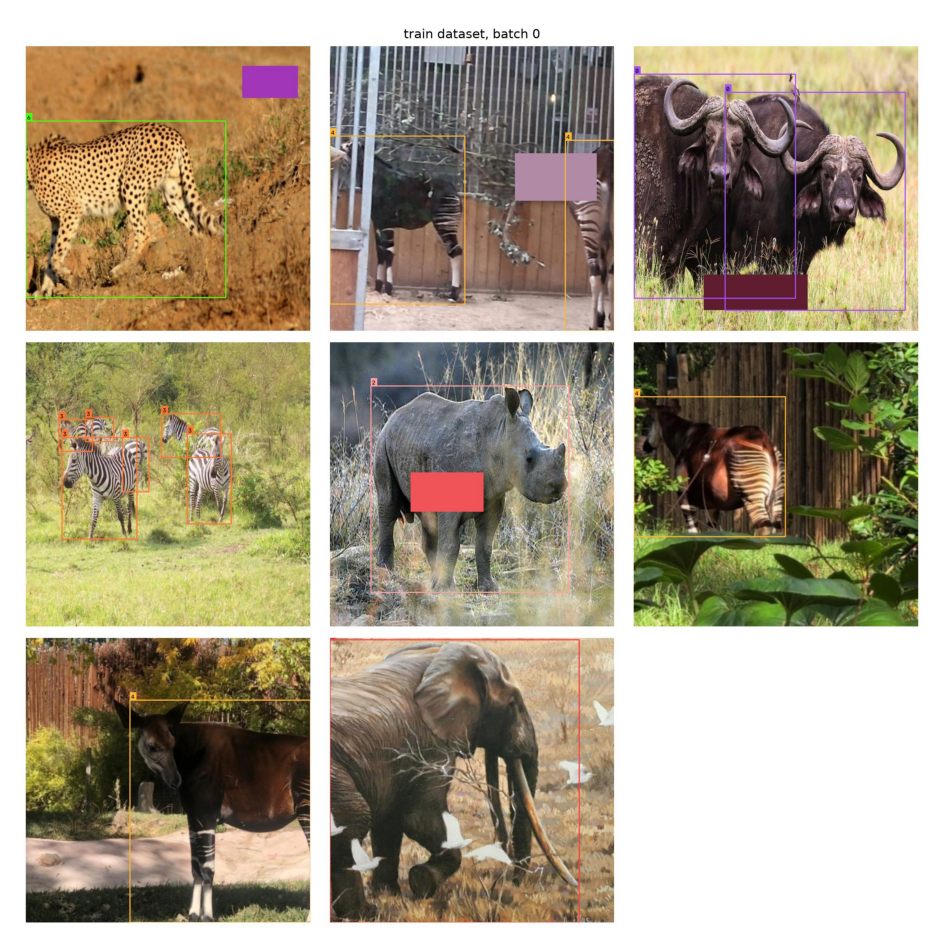

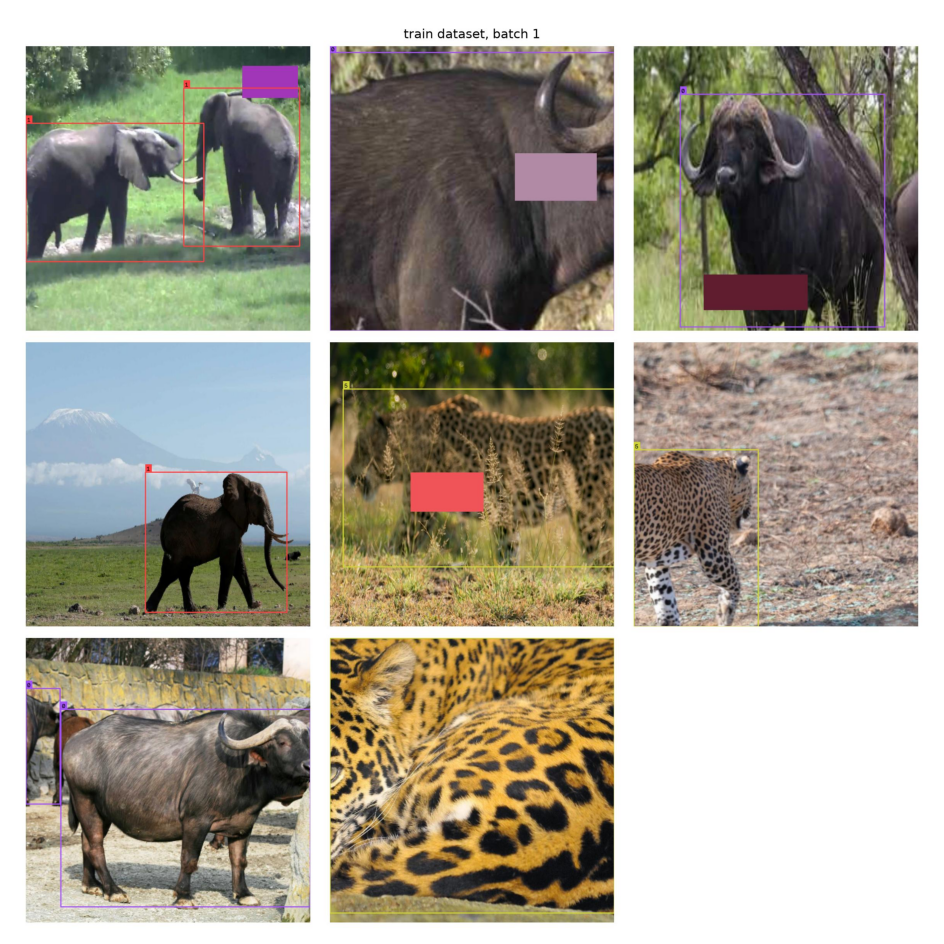

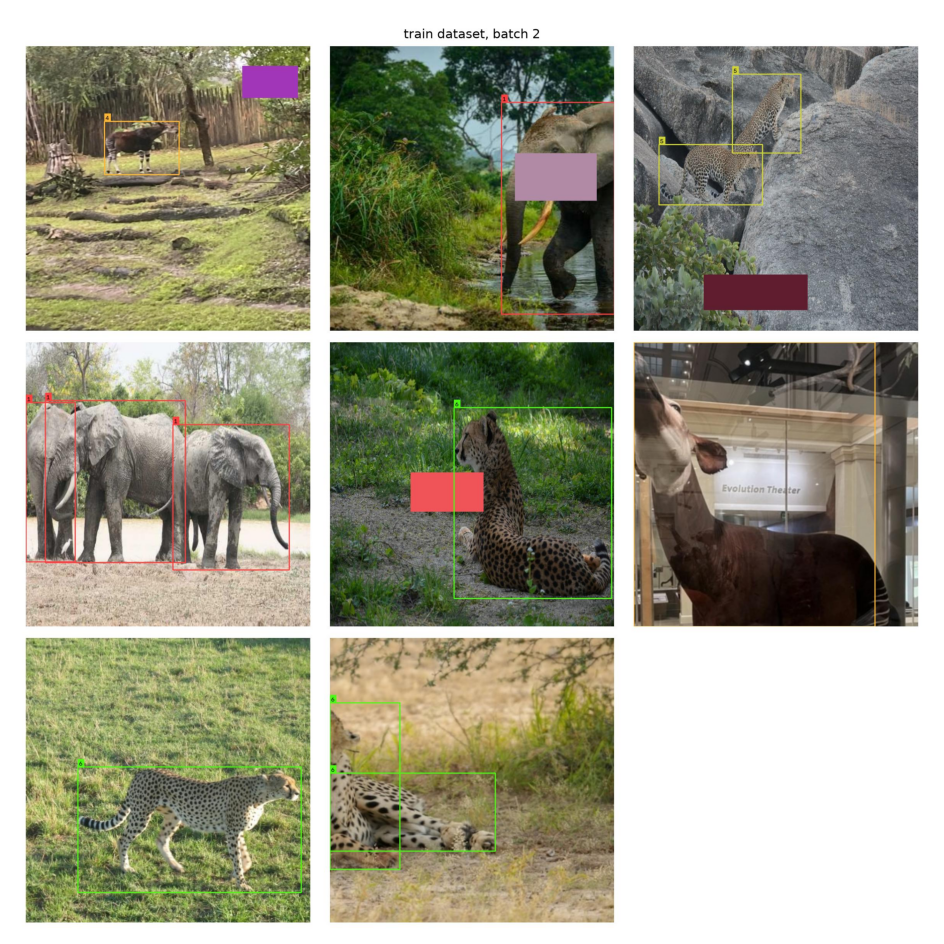

Grids copied to: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\training_results\rf-detr-erasing-only\dataset_grids


In [9]:
grids_dir = OUTPUT_DIR / 'dataset_grids'
train_grids = sorted(grids_dir.glob('train_batch*_grid.jpg'))
assert train_grids, f'No grids in {grids_dir}; run the training cell with save_dataset_grids=True'

(RESULTS_DIR / 'dataset_grids').mkdir(exist_ok=True)
for grid_path in train_grids:
    shutil.copy2(grid_path, RESULTS_DIR / 'dataset_grids' / grid_path.name)
    fig, ax = plt.subplots(figsize=(12, 12))
    ax.imshow(cv2.cvtColor(cv2.imread(str(grid_path)), cv2.COLOR_BGR2RGB))
    ax.axis('off')
    plt.show()
print('Grids copied to:', RESULTS_DIR / 'dataset_grids')

In [10]:
# RF-DETR logs every metric to metrics.csv; collapse it to one row per epoch
history = pd.read_csv(OUTPUT_DIR / 'metrics.csv').groupby('epoch').last()

columns = {
    'train/loss_epoch': 'train_loss',
    'train/loss': 'train_loss',
    'val/loss': 'val_loss',
    'train/mAP_50': 'train_mAP50',
    'val/mAP_50': 'mAP50',
    'train/mAP_50_95': 'train_mAP50-95',
    'val/mAP_50_95': 'mAP50-95',
    'train/precision': 'train_precision',
    'val/precision': 'precision',
    'val/recall': 'recall',
    'val/F1': 'F1'
}
columns = {k: v for k, v in columns.items() if k in history.columns}

epoch_metrics = history[list(columns)].rename(columns=columns)
epoch_metrics = epoch_metrics.loc[:, ~epoch_metrics.columns.duplicated()]
print(epoch_metrics.round(4).to_string())

epoch_metrics.to_csv(RESULTS_DIR / 'results.csv')
shutil.copy2(OUTPUT_DIR / 'metrics.csv', RESULTS_DIR / 'metrics.csv')
shutil.copy2(OUTPUT_DIR / 'training_config.json', RESULTS_DIR / 'training_config.json')
print('Saved per-epoch results to:', RESULTS_DIR / 'results.csv')

       train_loss  val_loss  train_mAP50   mAP50  train_mAP50-95  mAP50-95  train_precision  precision  recall      F1
epoch                                                                                                                 
0          6.1006    4.7397       0.7409  0.9434          0.6417    0.8456           0.7118     0.8030  0.8772  0.8134
1          4.6572    3.8900       0.9483  0.9796          0.8339    0.8859           0.9347     0.9547  0.9374  0.9454
2          4.3141    3.7782       0.9656  0.9799          0.8574    0.8882           0.9480     0.9738  0.9262  0.9489
3          4.1049    3.6149       0.9718  0.9810          0.8697    0.8920           0.9636     0.9656  0.9350  0.9497
4          4.1068    3.7541       0.9752  0.9803          0.8767    0.8869           0.9611     0.9636  0.9411  0.9519
5          3.8852    3.7012       0.9743  0.9797          0.8781    0.8904           0.9679     0.9567  0.9447  0.9502
6          3.7545    3.5691       0.9800  0.9825

In [5]:
def predict_split(model, split):
    ds = sv.DetectionDataset.from_yolo(
        images_directory_path=str(DATASET_DIR / 'images' / split),
        annotations_directory_path=str(DATASET_DIR / 'labels' / split),
        data_yaml_path=str(DATA)
    )
    predictions, targets = [], []
    for image_path, _, annotations in ds:
        predictions.append(model.predict(image_path, threshold=0.01))
        targets.append(annotations)
    return predictions, targets


def evaluate(model, split, predictions=None, targets=None):
    if predictions is None:
        predictions, targets = predict_split(model, split)

    map_result = MeanAveragePrecision().update(predictions, targets).compute()

    # Precision / recall at the confidence with the best F1 (same convention as Ultralytics' mp / mr)
    best = {'F1': -1.0}
    for conf in np.arange(0.05, 0.96, 0.05):
        kept = [p[p.confidence >= conf] for p in predictions]
        precision = Precision(averaging_method=AveragingMethod.MACRO).update(kept, targets).compute().precision_at_50
        recall = Recall(averaging_method=AveragingMethod.MACRO).update(kept, targets).compute().recall_at_50
        f1 = 2 * precision * recall / (precision + recall + 1e-9)
        if f1 > best['F1']:
            best = {'Precision': float(precision), 'Recall': float(recall), 'F1': float(f1), 'Confidence': round(float(conf), 2)}

    return {
        'Precision': best['Precision'],
        'Recall': best['Recall'],
        'mAP50': float(map_result.map50),
        'mAP50-95': float(map_result.map50_95),
        'mAP75': float(map_result.map75),
        'Best-F1 confidence': best['Confidence']
    }

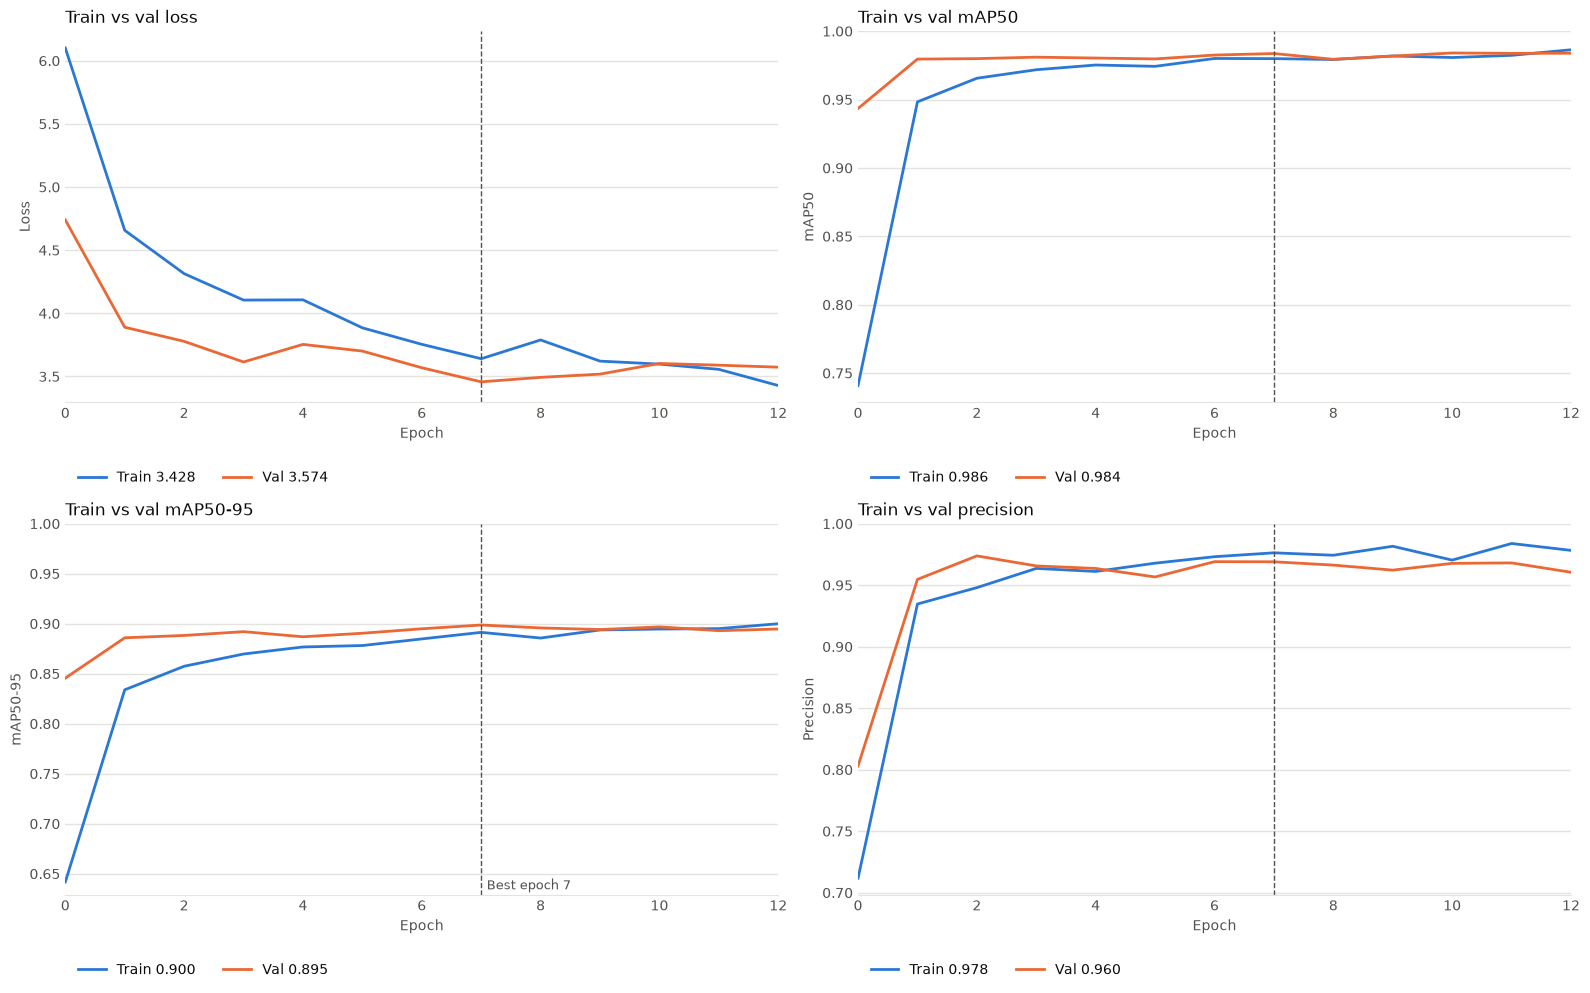

In [12]:
TRAIN_COLOR, VAL_COLOR = '#2a78d6', '#eb6834'  # same in every panel: blue = train, orange = val


def plot_train_val(ax, train_key, val_key, title, ylabel):
    for key, label, color in ((train_key, 'Train', TRAIN_COLOR), (val_key, 'Val', VAL_COLOR)):
        if key not in epoch_metrics:
            continue
        series = epoch_metrics[key].dropna()
        ax.plot(series.index, series.values, color=color, linewidth=2, label=f'{label} {series.iloc[-1]:.3f}')
    ax.set_title(title, loc='left', fontsize=12, color=TEXT)
    ax.set_xlabel('Epoch', color=MUTED)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.set_xlim(epoch_metrics.index.min(), epoch_metrics.index.max())
    ax.grid(axis='y', color=GRID, linewidth=1)
    ax.tick_params(colors=MUTED, length=0, labelbottom=True)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(GRID)
    # Train and val often end within a few points of each other, so the legend carries the final values
    ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(0, -0.15), ncol=2, labelcolor=TEXT)


panels = [
    ('train_loss', 'val_loss', 'Train vs val loss', 'Loss'),
    ('train_mAP50', 'mAP50', 'Train vs val mAP50', 'mAP50'),
    ('train_mAP50-95', 'mAP50-95', 'Train vs val mAP50-95', 'mAP50-95'),
    ('train_precision', 'precision', 'Train vs val precision', 'Precision')
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
best_epoch = epoch_metrics['mAP50-95'].idxmax()
for ax, (train_key, val_key, title, ylabel) in zip(axes.flat, panels):
    plot_train_val(ax, train_key, val_key, title, ylabel)
    if ylabel != 'Loss':
        ax.set_ylim(top=1)
    ax.axvline(best_epoch, color=MUTED, linewidth=1, linestyle='--')
axes[1, 0].annotate(f'Best epoch {best_epoch}', (best_epoch, 0), xycoords=('data', 'axes fraction'),
                    xytext=(4, 4), textcoords='offset points', fontsize=9, color=MUTED)

fig.tight_layout()
fig.savefig(RESULTS_DIR / 'train_val_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
best_path = OUTPUT_DIR / 'checkpoint_best_total.pth'
best_model = from_checkpoint(best_path)

metrics = evaluate(best_model, 'val')

print('Best weights:', best_path)
for name, value in metrics.items():
    print(f'{name}: {value:.4f}')

C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\detr.py:639: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\detr.py:639: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\detr.py:639: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-22 01:46:05] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-22 01:46:05] [WARNING] rf-detr - Using patch size 16 instead of 

Best weights: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\rfdetr_runs\wildlife_rfdetr_medium_erasing_only\checkpoint_best_total.pth
Precision: 0.9606
Recall: 0.9612
mAP50: 0.9843
mAP50-95: 0.8975
mAP75: 0.9661
Best-F1 confidence: 0.4500


## Save the final trained model

Copies the best checkpoint to `ai-applications/trained_models`.

In [14]:
final_model_path = TRAINED_MODEL_DIR / 'rfdetr_erasing_10.pth'
shutil.copy2(best_path, final_model_path)

# Keep only the final model: delete RF-DETR's training checkpoints from the run folder
for checkpoint in [*OUTPUT_DIR.glob('*.pth'), *OUTPUT_DIR.glob('*.ckpt')]:
    checkpoint.unlink()

print('Final trained model saved to:', final_model_path)

Final trained model saved to: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\trained_models\rfdetr_erasing_10.pth


## Evaluate on the test split

In [15]:
test_predictions, test_targets = predict_split(best_model, 'test')
test_metrics = evaluate(best_model, 'test', test_predictions, test_targets)

results = {
    'Model': MODEL_NAME,
    'Precision': test_metrics['Precision'],
    'Recall': test_metrics['Recall'],
    'mAP50': test_metrics['mAP50'],
    'mAP50-95': test_metrics['mAP50-95'],
    'mAP75': test_metrics['mAP75'],
    'Training time (min)': globals().get('training_time_min'),  # None if the training cell wasn't run this session
    'Best weights': final_model_path.relative_to(PROJECT_ROOT).as_posix()
}

evaluation_df = pd.DataFrame([results])
print(evaluation_df.round(4).to_string(index=False))
print('Best-F1 confidence:', test_metrics['Best-F1 confidence'])

# Same file names / columns as rtdetr_evaluation.csv so the models can be compared directly
evaluation_df.to_csv(RESULTS_DIR / 'rfdetr_evaluation.csv', index=False)
evaluation_df.to_json(RESULTS_DIR / 'rfdetr_evaluation.json', orient='records', indent=2)
print('Saved results to:', RESULTS_DIR / 'rfdetr_evaluation.csv')
print('Saved results to:', RESULTS_DIR / 'rfdetr_evaluation.json')

                   Model  Precision  Recall  mAP50  mAP50-95  mAP75  Training time (min)                                         Best weights
RF-DETR-M + erasing only     0.9735  0.9692 0.9879    0.8984  0.951             103.1382 ai-applications/trained_models/rfdetr_erasing_10.pth
Best-F1 confidence: 0.5
Saved results to: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\training_results\rf-detr-erasing-only\rfdetr_evaluation.csv
Saved results to: C:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\training_results\rf-detr-erasing-only\rfdetr_evaluation.json


## Confusion matrix on the test split

Rows are the true class, columns the predicted class. A `background` column means a missed animal; a `background` row means a false detection with no real animal behind it.

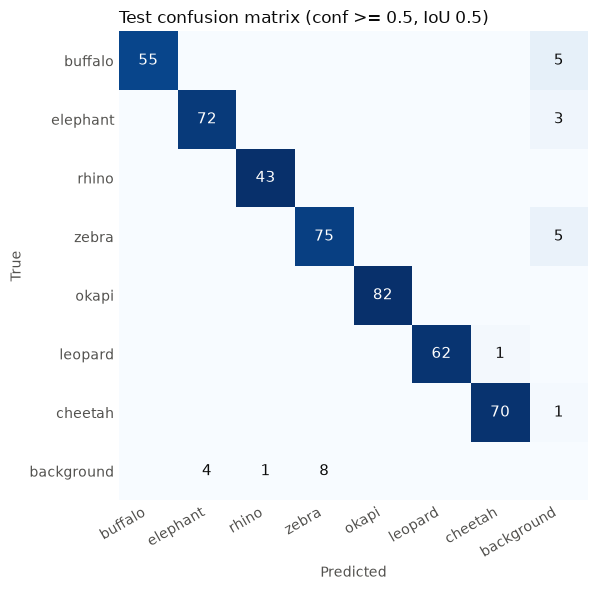

          Correct  Wrong class  Missed  False detections  Classification accuracy
buffalo        55            0       5                 0                   1.0000
elephant       72            0       3                 4                   1.0000
rhino          43            0       0                 1                   1.0000
zebra          75            0       5                 8                   1.0000
okapi          82            0       0                 0                   1.0000
leopard        62            1       0                 0                   0.9841
cheetah        70            0       1                 0                   1.0000


In [16]:
# Same confidence cutoff as the reported precision/recall, and IoU 0.5 like precision_at_50
conf_threshold = test_metrics['Best-F1 confidence']
confusion = sv.ConfusionMatrix.from_detections(
    predictions=test_predictions,
    targets=test_targets,
    classes=CLASS_NAMES,
    conf_threshold=conf_threshold,
    iou_threshold=0.5
)

labels = CLASS_NAMES + ['background']
counts = confusion.matrix.astype(int)  # last row/column = background
# Shade each true class by its share of that row; the background row has no true total, so leave it unshaded
row_share = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)
row_share[-1] = 0

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(row_share, cmap='Blues', vmin=0, vmax=1)
for i in range(len(labels)):
    for j in range(len(labels)):
        if counts[i, j]:
            ax.text(j, i, counts[i, j], ha='center', va='center', fontsize=11,
                    color='white' if row_share[i, j] > 0.5 else TEXT)
ax.set_xticks(range(len(labels)), labels, rotation=30, ha='right')
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel('Predicted', color=MUTED)
ax.set_ylabel('True', color=MUTED)
ax.set_title(f'Test confusion matrix (conf >= {conf_threshold}, IoU 0.5)', loc='left', fontsize=12, color=TEXT)
ax.tick_params(colors=MUTED, length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

animals = counts[:-1, :-1]  # true animal vs predicted animal, ignoring background
per_class = pd.DataFrame({
    'Correct': np.diag(animals),
    'Wrong class': animals.sum(axis=1) - np.diag(animals),
    'Missed': counts[:-1, -1],
    'False detections': counts[-1, :-1]
}, index=CLASS_NAMES)
# Of the animals the model found, how many got the right label
per_class['Classification accuracy'] = per_class['Correct'] / (per_class['Correct'] + per_class['Wrong class'])
print(per_class.round(4).to_string())
per_class.to_csv(RESULTS_DIR / 'confusion_per_class.csv')

## Threshold sweep

Same sweep as Section 10 of `YOLO11n_RTDETR_flip_rotation_mosaic_experiments_with_plots.ipynb`: the final model is scored on val and test at
a range of confidence cutoffs (IoU 0.5), and the per-class counts come from each split's confusion matrix:

- **Correct**: predicted as the class, and it is that class
- **Wrong**: predicted as the class, but it is another animal
- **FP**: predicted as the class, but there is no animal there
- **Missed**: an animal of the class that was not detected

**Recall** = Correct / (Correct + Wrong + Missed), **operational accuracy** = Correct / (Correct + Wrong + FP) (how many of the boxes the model
outputs are right) and **pure accuracy** = Correct / (Correct + Wrong) (how many of the detected animals got the right label). mAP is computed
on the boxes left after each cutoff, like Ultralytics' `val(conf=...)`.

In [7]:
CONFS = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90]
SPLITS = ['val', 'test']

# Load the saved final model so this section also runs after a kernel restart (the run's checkpoints are deleted after copying)
sweep_model = from_checkpoint(TRAINED_MODEL_DIR / 'rfdetr_erasing_10_best.pth')
n = len(CLASS_NAMES)

rows = []
for split in SPLITS:
    predictions, targets = predict_split(sweep_model, split)
    for conf in CONFS:
        kept = [p[p.confidence >= conf] for p in predictions]
        map_result = MeanAveragePrecision().update(kept, targets).compute()
        # rows = true class, columns = predicted class, last row/column = background
        cm = sv.ConfusionMatrix.from_detections(
            predictions=predictions,
            targets=targets,
            classes=CLASS_NAMES,
            conf_threshold=conf,
            iou_threshold=0.5
        ).matrix.astype(int)
        for c in range(n):
            rows.append({
                'Split': split, 'Conf': conf, 'Class': CLASS_NAMES[c],
                'Correct': cm[c, c],
                'Wrong': cm[:n, c].sum() - cm[c, c],  # predicted as this class, but another animal
                'FP': cm[n, c],  # predicted as this class, but no animal there
                'Missed': cm[c, n],  # an animal of this class that was not detected
                'mAP50': float(map_result.map50), 'mAP50-95': float(map_result.map50_95),
            })
    print(f'Done: {split}')

per_class_sweep = pd.DataFrame(rows)
per_class_sweep['Op. acc.'] = per_class_sweep.Correct / (per_class_sweep.Correct + per_class_sweep.Wrong + per_class_sweep.FP)
per_class_sweep['Pure acc.'] = per_class_sweep.Correct / (per_class_sweep.Correct + per_class_sweep.Wrong)

keys = ['Split', 'Conf']
sweep = per_class_sweep.groupby(keys)[['Correct', 'Wrong', 'FP', 'Missed']].sum()
sweep['Recall'] = sweep.Correct / (sweep.Correct + sweep.Wrong + sweep.Missed)
sweep['Op. acc. (pooled)'] = sweep.Correct / (sweep.Correct + sweep.Wrong + sweep.FP)
sweep['Op. acc. (mean)'] = per_class_sweep.groupby(keys)['Op. acc.'].mean()
sweep['Pure acc. (pooled)'] = sweep.Correct / (sweep.Correct + sweep.Wrong)
sweep = sweep.join(per_class_sweep.groupby(keys)[['mAP50', 'mAP50-95']].first()).reset_index()

print(sweep.round(4).to_string(index=False))
sweep.to_csv(RESULTS_DIR / 'threshold_sweep.csv', index=False)
per_class_sweep.to_csv(RESULTS_DIR / 'threshold_sweep_per_class.csv', index=False)
print('Saved sweep to:', RESULTS_DIR / 'threshold_sweep.csv')

C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\detr.py:639: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\detr.py:639: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\detr.py:639: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-23 17:17:24] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-23 17:17:24] [WARNING] rf-detr - Using patch size 16 instead of 

Done: val
Done: test
Split  Conf  Correct  Wrong  FP  Missed  Recall  Op. acc. (pooled)  Op. acc. (mean)  Pure acc. (pooled)  mAP50  mAP50-95
 test  0.25      466      1  57       7  0.9831             0.8893           0.9068              0.9979 0.9757    0.8833
 test  0.30      466      1  47       7  0.9831             0.9066           0.9187              0.9979 0.9757    0.8828
 test  0.35      465      1  35       8  0.9810             0.9281           0.9380              0.9979 0.9732    0.8794
 test  0.40      465      1  26       8  0.9810             0.9451           0.9532              0.9979 0.9732    0.8788
 test  0.45      463      1  19      10  0.9768             0.9586           0.9633              0.9978 0.9707    0.8770
 test  0.50      459      1  14      14  0.9684             0.9684           0.9719              0.9978 0.9628    0.8720
 test  0.60      445      1   9      28  0.9388             0.9780           0.9789              0.9978 0.9342    0.8546
 test  0.70

### Operational accuracy vs recall

The final threshold is picked on val, as in the YOLO / RT-DETR notebook: the highest confidence whose recall stays within 2 points of the recall at
conf 0.25. The test panel shows the same threshold, to check it holds on unseen images.

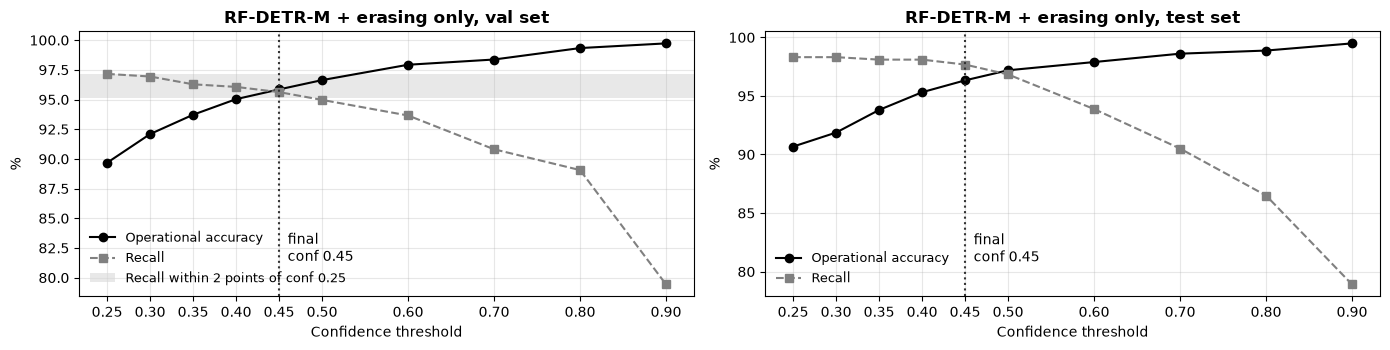

Final confidence threshold (picked on val): 0.45
Split  Conf  Correct  Wrong  FP  Missed  Recall  Op. acc. (pooled)  Op. acc. (mean)  Pure acc. (pooled)  mAP50  mAP50-95
 test  0.45      463      1  19      10  0.9768             0.9586           0.9633              0.9978 0.9707    0.8770
  val  0.45      437      2  19      18  0.9562             0.9541           0.9585              0.9954 0.9539    0.8689


In [8]:
val_sweep = sweep[sweep.Split == 'val'].sort_values('Conf')
val_recall = val_sweep.Recall.values * 100
r0 = val_recall[0]
# Final threshold: highest conf whose val recall is within 2 points of the recall at conf 0.25
final_conf = val_sweep.Conf.values[val_recall >= r0 - 2].max()

fig, axes = plt.subplots(1, len(SPLITS), figsize=(7 * len(SPLITS), 3.6))
for ax, split in zip(np.atleast_1d(axes), SPLITS):
    d = sweep[sweep.Split == split].sort_values('Conf')
    conf = d.Conf.values
    op = d['Op. acc. (mean)'].values * 100
    rec = d.Recall.values * 100

    ax.plot(conf, op, 'k-o', label='Operational accuracy')
    ax.plot(conf, rec, '--s', color='0.5', label='Recall')
    if split == 'val':
        ax.axhspan(r0 - 2, r0, color='0.85', alpha=0.6, lw=0, label='Recall within 2 points of conf 0.25')
    ax.axvline(final_conf, color='0.2', ls=':', lw=1.5)
    ax.text(final_conf + 0.01, ax.get_ylim()[0] + 3, f'final\nconf {final_conf:.2f}', fontsize=10)

    ax.set_xticks(conf)
    ax.set_xlabel('Confidence threshold')
    ax.set_ylabel('%')
    ax.set_title(f'{MODEL_NAME}, {split} set', fontweight='bold')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower left', fontsize=9, frameon=False)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'threshold_sweep.png', dpi=200)
plt.show()

print(f'Final confidence threshold (picked on val): {final_conf:.2f}')
print(sweep[sweep.Conf == final_conf].round(4).to_string(index=False))

## Inference on a sample test image

Test image: C:\Users\zheng\Documents\ISY5002-PRS-G14\data\wildlife_dataset\images\test\1 (101).jpg


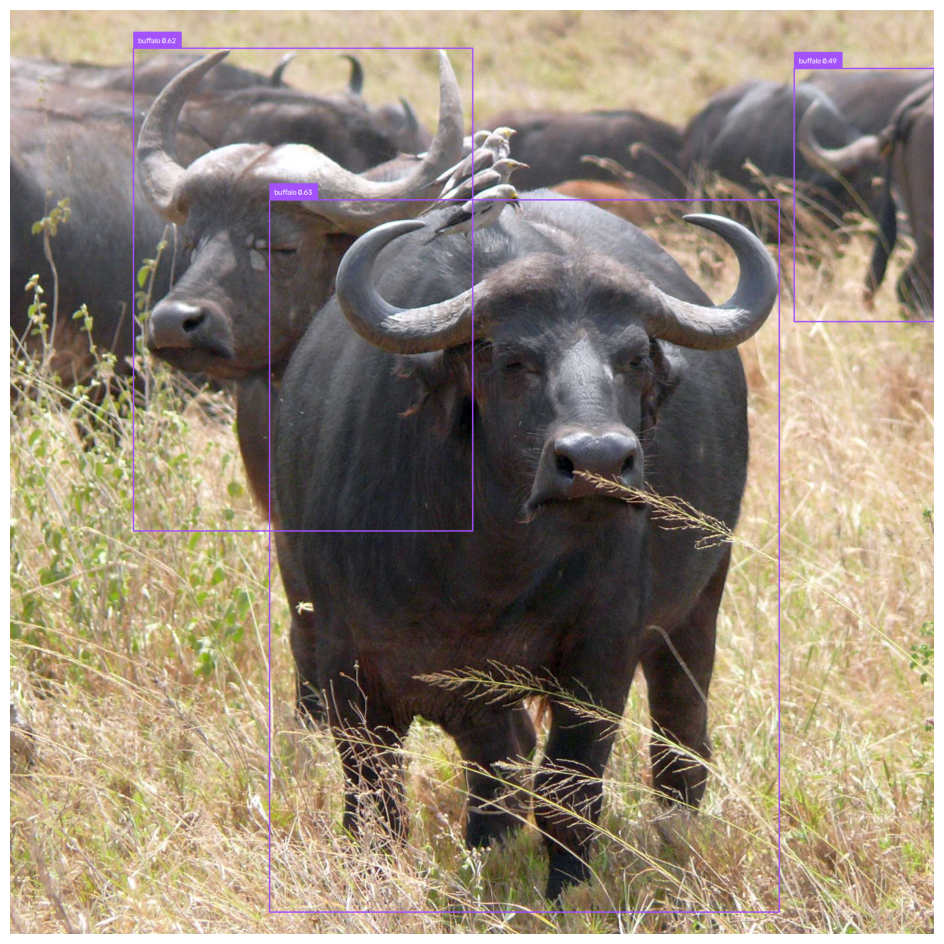

In [17]:
TEST_IMAGE = next(p for p in test_dir.iterdir() if p.is_file())
print('Test image:', TEST_IMAGE)

prediction = best_model.predict(str(TEST_IMAGE), threshold=0.35)

image = cv2.imread(str(TEST_IMAGE))
labels = [f'{CLASS_NAMES[c]} {p:.2f}' for c, p in zip(prediction.class_id, prediction.confidence)]
annotated = sv.BoxAnnotator().annotate(image.copy(), prediction)
annotated = sv.LabelAnnotator().annotate(annotated, prediction, labels=labels)
cv2.imwrite(str(RESULTS_DIR / 'sample_prediction.jpg'), annotated)
sv.plot_image(annotated)

In [18]:
for xyxy, class_id, confidence in zip(prediction.xyxy, prediction.class_id, prediction.confidence):
    x1, y1, x2, y2 = xyxy.tolist()
    print({
        'class': CLASS_NAMES[int(class_id)],
        'confidence': round(float(confidence), 4),
        'box': [round(x1, 2), round(y1, 2), round(x2, 2), round(y2, 2)]
    })

{'class': 'buffalo', 'confidence': 0.6344, 'box': [539.14, 394.79, 1598.6, 1874.14]}
{'class': 'buffalo', 'confidence': 0.6171, 'box': [256.75, 79.41, 961.26, 1082.46]}
{'class': 'buffalo', 'confidence': 0.4854, 'box': [1629.31, 121.09, 1920.0, 647.67]}


## Wrongly classified test images

Test images where at least one animal was detected (IoU >= 0.5) but given the wrong class, using the same confidence cutoff as the confusion matrix. These are the images behind the off-diagonal counts in the matrix above. Green boxes are the ground truth, red boxes the predictions.

Wrongly classified test images: 1 / 331 (conf >= 0.5, IoU 0.5)
  5 (276).jpg: leopard -> cheetah


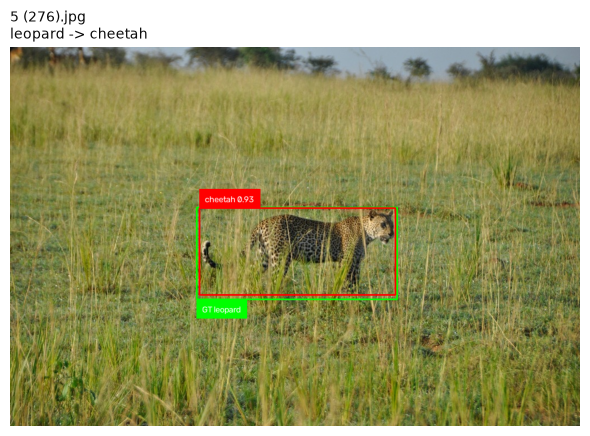

In [19]:
# Same image order as predict_split, so index i lines up with test_predictions[i] / test_targets[i]
test_ds = sv.DetectionDataset.from_yolo(
    images_directory_path=str(DATASET_DIR / 'images' / 'test'),
    annotations_directory_path=str(DATASET_DIR / 'labels' / 'test'),
    data_yaml_path=str(DATA)
)

wrong = []
for image_path, prediction, target in zip(test_ds.image_paths, test_predictions, test_targets):
    # Per-image confusion matrix with the same settings as the test matrix above
    image_counts = sv.ConfusionMatrix.from_detections(
        predictions=[prediction],
        targets=[target],
        classes=CLASS_NAMES,
        conf_threshold=conf_threshold,
        iou_threshold=0.5
    ).matrix.astype(int)[:-1, :-1]  # animals only, ignoring background
    np.fill_diagonal(image_counts, 0)  # keep only true class != predicted class
    mistakes = [f'{CLASS_NAMES[t]} -> {CLASS_NAMES[p]}' + (f' x{image_counts[t, p]}' if image_counts[t, p] > 1 else '')
                for t, p in zip(*np.nonzero(image_counts))]
    if mistakes:
        wrong.append((image_path, prediction[prediction.confidence >= conf_threshold], target, mistakes))

print(f'Wrongly classified test images: {len(wrong)} / {len(test_ds)} (conf >= {conf_threshold}, IoU 0.5)')
for image_path, _, _, mistakes in wrong:
    print(f'  {Path(image_path).name}: {", ".join(mistakes)}')

if wrong:
    cols = min(3, len(wrong))
    rows = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5 * rows), squeeze=False)
    for ax, (image_path, kept, target, mistakes) in zip(axes.flat, wrong):
        image = cv2.imread(image_path)
        image = sv.BoxAnnotator(color=sv.Color.GREEN).annotate(image, target)
        image = sv.LabelAnnotator(color=sv.Color.GREEN, text_position=sv.Position.BOTTOM_LEFT).annotate(
            image, target, labels=[f'GT {CLASS_NAMES[c]}' for c in target.class_id])
        image = sv.BoxAnnotator(color=sv.Color.RED).annotate(image, kept)
        image = sv.LabelAnnotator(color=sv.Color.RED).annotate(
            image, kept, labels=[f'{CLASS_NAMES[c]} {p:.2f}' for c, p in zip(kept.class_id, kept.confidence)])
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(f'{Path(image_path).name}\n{", ".join(mistakes)}', loc='left', fontsize=10, color=TEXT)
        ax.axis('off')
    for ax in axes.flat[len(wrong):]:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / 'misclassified_test_images.png', dpi=150, bbox_inches='tight')
    plt.show()